# 🔄 Clase 4 — Transfer Learning con MobileNetV2 y tus propias fotos
### Módulo 2: Deep Learning · Diplomatura en IA · UTN 2026

---

**La idea central de esta clase:**
Google entrenó MobileNetV2 durante semanas con 14 millones de imágenes. Vos vas a aprovecharte de todo ese trabajo para entrenar tu propio clasificador **en 5 minutos**, con **solo 20 fotos tuyas**.

**En este notebook vas a:**
1. Entender qué es Transfer Learning y por qué funciona
2. Subir tus propias fotos de 2 o 3 categorías
3. Usar MobileNetV2 como base y agregar tus capas encima
4. Entrenar solo las capas nuevas (las de MobileNet quedan congeladas)
5. Probar el modelo con una foto nueva
6. Comparar: ¿qué pasa si entrenamos desde cero?

> ⏱️ **Tiempo:** ~30 min de configuración + 5 min de entrenamiento

---

## Contexto — ¿Por qué Transfer Learning?

Imaginá que querés aprender a tocar jazz. Tenés dos opciones:

- **Opción A (desde cero):** aprender teoría musical, solfeo, escalas, acordes, ritmo, armonía… y recién después aprender jazz. Necesitás años.
- **Opción B (transfer learning):** ya sabés tocar piano clásico. Tomás eso como base y solo aprendés las diferencias del jazz. En semanas tenés resultados.

Las redes neuronales funcionan igual. MobileNetV2 ya sabe detectar bordes, texturas, formas, partes de objetos. **Vos solo le enseñás las diferencias entre tus categorías.**

### ¿Qué aprendió MobileNetV2 en sus capas?

```
Capas tempranas  →  bordes, curvas, gradientes (genérico, aplica a cualquier imagen)
Capas medias     →  texturas, patrones, partes (ruedas, ojos, hojas, ladrillos...)
Capas tardías    →  conceptos complejos ("cara de perro", "carrocería de auto"...)
Capa final orig. →  1000 clases de ImageNet (que vamos a REEMPLAZAR por las tuyas)
```

**Nuestra estrategia:**
- 🔒 Congelar las capas de MobileNetV2 (no las tocamos)
- ✏️ Agregar capas nuevas encima
- 🏋️ Entrenar solo las capas nuevas con tus fotos

In [3]:
# ─── INSTALACIÓN Y CONFIGURACIÓN ────────────────────────────────────
import os, shutil, zipfile, random, warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.preprocessing.image import load_img, img_to_array

from google.colab import files
from IPython.display import HTML, display, clear_output
import ipywidgets as widgets

warnings.filterwarnings('ignore')

print('✅ Librerías listas')
print(f'   TensorFlow: {tf.__version__}')

# Verificar GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'   GPU disponible: {gpus[0].name} ⚡')
else:
    print('   CPU solamente (el entrenamiento igual es rápido con Transfer Learning)')

# Semilla de reproducibilidad
tf.random.set_seed(42)
np.random.seed(42)

✅ Librerías listas
   TensorFlow: 2.20.0
   GPU disponible: /physical_device:GPU:0 ⚡


---
## Parte 1 — Subir tus fotos

### ¿Qué fotos subir?

Elegí **2 o 3 categorías** que sean visualmente distinguibles. Ejemplos:
- 🐱 vs 🐶 (gatos vs perros)
- 🍎 vs 🍌 (frutas)
- ☕ vs 🍵 (bebidas)
- 🏠 vs 🌳 (interior vs exterior)
- 😀 vs 😐 (expresiones faciales)
- **Cualquier cosa que tengas en el teléfono** — ¡usá fotos propias!

### ¿Cuántas fotos?
- **Mínimo:** 10 por categoría (funciona con Transfer Learning)
- **Recomendado:** 20–30 por categoría
- **Más = mejor**, pero no necesario para esta demo

### ¿Formato?
- JPG o PNG
- Cualquier tamaño (las redimensionamos a 224×224 automáticamente)

---
**Ejecutá la siguiente celda y vas a poder subir tus fotos.**
Subí todas las fotos de cada categoría juntas — luego te pido que les asignes el nombre.

In [4]:
# ─── SUBIR FOTOS ────────────────────────────────────────────────────
print('📁 Seleccioná todas las fotos de tu PRIMERA categoría:')
print('   (podés seleccionar múltiples archivos con Ctrl+Click)\n')

uploaded = files.upload()

print(f'\n✅ {len(uploaded)} archivos subidos:')
for nombre in uploaded:
    print(f'   → {nombre}')

📁 Seleccioná todas las fotos de tu PRIMERA categoría:
   (podés seleccionar múltiples archivos con Ctrl+Click)



Saving Beagle-cordoba.jpg to Beagle-cordoba.jpg
Saving Captura de pantalla 2026-06-07 192943.png to Captura de pantalla 2026-06-07 192943.png
Saving Captura de pantalla 2026-06-07 193030.png to Captura de pantalla 2026-06-07 193030.png
Saving Captura de pantalla 2026-06-07 193045.png to Captura de pantalla 2026-06-07 193045.png
Saving Captura de pantalla 2026-06-07 193059.png to Captura de pantalla 2026-06-07 193059.png
Saving Captura de pantalla 2026-06-07 193112.png to Captura de pantalla 2026-06-07 193112.png
Saving Captura de pantalla 2026-06-07 193124.png to Captura de pantalla 2026-06-07 193124.png
Saving descarga.png to descarga.png
Saving perro.png to perro.png
Saving perro-de-raza-beagle_67c65dda_230302133829_900x900.jpg to perro-de-raza-beagle_67c65dda_230302133829_900x900.jpg

✅ 10 archivos subidos:
   → Beagle-cordoba.jpg
   → Captura de pantalla 2026-06-07 192943.png
   → Captura de pantalla 2026-06-07 193030.png
   → Captura de pantalla 2026-06-07 193045.png
   → Captura 

In [5]:
# ─── NOMBRAR LA PRIMERA CATEGORÍA ───────────────────────────────────
# ✏️ CAMBIÁ ESTE VALOR por el nombre de tus fotos
CATEGORIA_1 = "perro"   # ← escribí aquí el nombre (sin espacios, en minúsculas)

# Crear la carpeta y mover las fotos
os.makedirs(f'dataset/train/{CATEGORIA_1}', exist_ok=True)
os.makedirs(f'dataset/val/{CATEGORIA_1}',   exist_ok=True)

archivos = list(uploaded.keys())
random.shuffle(archivos)

# 80% train, 20% val
split = max(1, int(len(archivos) * 0.8))
for f in archivos[:split]:
    shutil.move(f, f'dataset/train/{CATEGORIA_1}/{f}')
for f in archivos[split:]:
    shutil.move(f, f'dataset/val/{CATEGORIA_1}/{f}')

print(f'✅ Categoría "{CATEGORIA_1}" organizada:')
print(f'   Train: {split} fotos')
print(f'   Val:   {len(archivos)-split} fotos')
print(f'\nAhora ejecutá la celda de arriba para subir la SEGUNDA categoría.')

✅ Categoría "perro" organizada:
   Train: 8 fotos
   Val:   2 fotos

Ahora ejecutá la celda de arriba para subir la SEGUNDA categoría.


In [6]:
# ─── SUBIR SEGUNDA CATEGORÍA ────────────────────────────────────────
print('📁 Seleccioná todas las fotos de tu SEGUNDA categoría:\n')
uploaded2 = files.upload()
print(f'\n✅ {len(uploaded2)} archivos subidos')

📁 Seleccioná todas las fotos de tu SEGUNDA categoría:



Saving Captura de pantalla 2026-06-07 193138.png to Captura de pantalla 2026-06-07 193138.png
Saving Captura de pantalla 2026-06-07 193152.png to Captura de pantalla 2026-06-07 193152.png
Saving Captura de pantalla 2026-06-07 193206.png to Captura de pantalla 2026-06-07 193206.png
Saving Captura de pantalla 2026-06-07 193217.png to Captura de pantalla 2026-06-07 193217.png
Saving Captura de pantalla 2026-06-07 193228.png to Captura de pantalla 2026-06-07 193228.png
Saving Captura de pantalla 2026-06-07 193238.png to Captura de pantalla 2026-06-07 193238.png
Saving gato.png to gato.png
Saving gato2.png to gato2.png
Saving images (1).png to images (1).png
Saving images.jfif to images.jfif

✅ 10 archivos subidos


In [7]:
# ─── NOMBRAR LA SEGUNDA CATEGORÍA ───────────────────────────────────
CATEGORIA_2 = "gato"   # ← cambiá por el nombre de tu segunda categoría

os.makedirs(f'dataset/train/{CATEGORIA_2}', exist_ok=True)
os.makedirs(f'dataset/val/{CATEGORIA_2}',   exist_ok=True)

archivos2 = list(uploaded2.keys())
random.shuffle(archivos2)
split2 = max(1, int(len(archivos2) * 0.8))
for f in archivos2[:split2]:
    shutil.move(f, f'dataset/train/{CATEGORIA_2}/{f}')
for f in archivos2[split2:]:
    shutil.move(f, f'dataset/val/{CATEGORIA_2}/{f}')

print(f'✅ Categoría "{CATEGORIA_2}" organizada:')
print(f'   Train: {split2} fotos')
print(f'   Val:   {len(archivos2)-split2} fotos')

✅ Categoría "gato" organizada:
   Train: 8 fotos
   Val:   2 fotos


📊 Dataset verificado:
   Categorías: ['gato', 'perro']
   N° de clases: 2

  TRAIN:
    gato: 7 imágenes
    perro: 8 imágenes
  VAL:
    gato: 2 imágenes
    perro: 2 imágenes


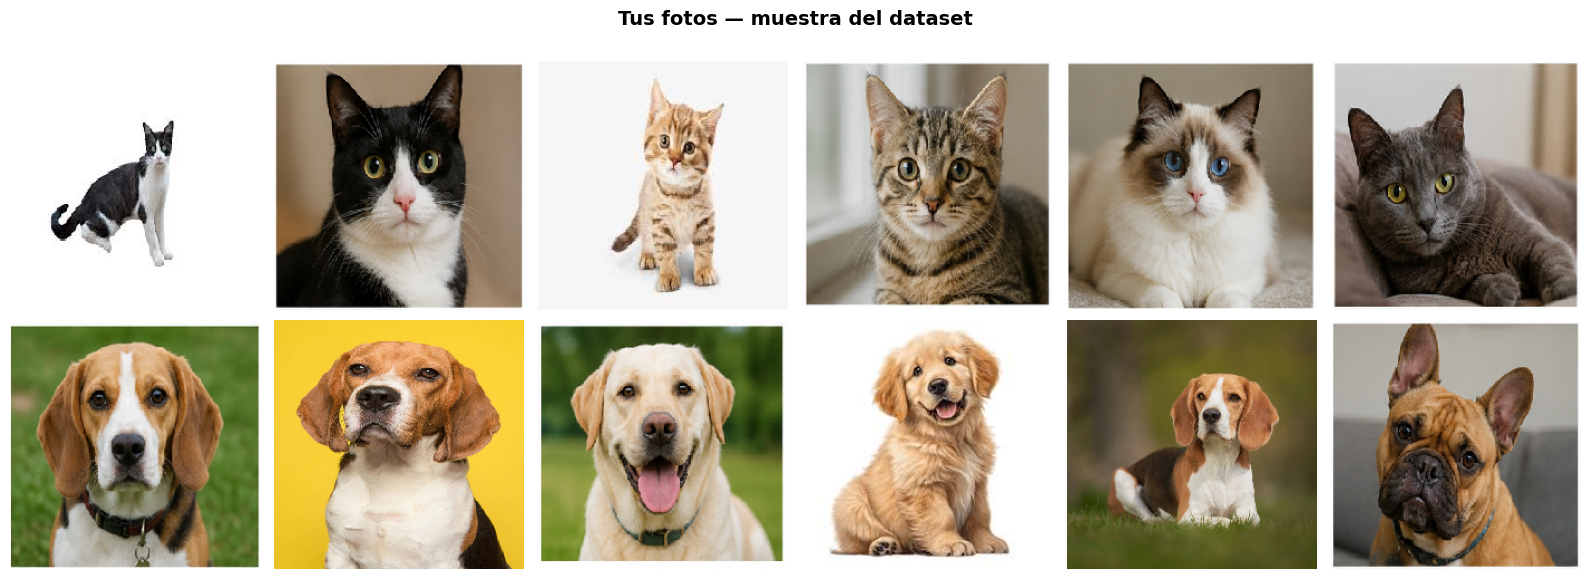

In [8]:
# ─── VERIFICAR EL DATASET ───────────────────────────────────────────
CATEGORIAS = sorted([d for d in os.listdir('dataset/train') if not d.startswith('.')])
N_CLASES   = len(CATEGORIAS)
IMG_SIZE   = (224, 224)
BATCH_SIZE = 8

print('📊 Dataset verificado:')
print(f'   Categorías: {CATEGORIAS}')
print(f'   N° de clases: {N_CLASES}')
print()
for split in ['train', 'val']:
    print(f'  {split.upper()}:')
    for cat in CATEGORIAS:
        path = f'dataset/{split}/{cat}'
        n = len([f for f in os.listdir(path) if f.lower().endswith(('.jpg','.jpeg','.png','.webp'))])
        print(f'    {cat}: {n} imágenes')

# Mostrar mosaico de fotos subidas
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
fig.suptitle('Tus fotos — muestra del dataset', fontsize=14, fontweight='bold')

for row, cat in enumerate(CATEGORIAS[:2]):
    path = f'dataset/train/{cat}'
    imgs = [f for f in os.listdir(path) if f.lower().endswith(('.jpg','.jpeg','.png','.webp'))][:6]
    for col, img_file in enumerate(imgs):
        ax = axes[row][col]
        img = load_img(f'{path}/{img_file}', target_size=(224,224))
        ax.imshow(img)
        ax.axis('off')
        if col == 0:
            ax.set_ylabel(cat, fontsize=12, fontweight='bold', color='#1E3A5F')
    # Rellenar celdas vacías
    for col in range(len(imgs), 6):
        axes[row][col].axis('off')

plt.tight_layout()
plt.show()

---
## Parte 2 — Cargar MobileNetV2 y construir el modelo

MobileNetV2 fue diseñado específicamente para correr en dispositivos móviles: es liviano (14MB), rápido y muy preciso. Fue entrenado con **ImageNet** — 14 millones de imágenes, 1000 categorías.

**Lo que vamos a hacer:**
1. Cargar MobileNetV2 **sin** su capa de clasificación final (`include_top=False`)
2. Congelar todos sus pesos (nadie los toca durante el entrenamiento)
3. Agregar encima: GlobalAveragePooling + Dense + Dropout + nuestra capa de salida
4. Solo esas capas nuevas se van a entrenar

In [9]:
# ─── CARGAR MOBILENETV2 ──────────────────────────────────────────────
print('Descargando MobileNetV2 pre-entrenado...')

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,        # sin la capa de clasificación de ImageNet
    weights='imagenet'        # con los pesos pre-entrenados
)

# CONGELAR todos los pesos de MobileNet
base_model.trainable = False

params_base    = base_model.count_params()
params_frozen  = sum([np.prod(v.shape) for v in base_model.non_trainable_variables])

print(f'\n✅ MobileNetV2 cargado')
print(f'   Capas totales: {len(base_model.layers)}')
print(f'   Parámetros: {params_base:,}')
print(f'   Estado: 🔒 CONGELADO (no se entrenan)')
print()
print('Las primeras y últimas capas de MobileNetV2:')
for capa in base_model.layers[:3]:
    # Usar capa.output.shape para obtener la forma de salida de forma robusta
    shape_info = capa.output.shape
    print(f'  [inicio] {capa.name}: {shape_info}')
print('  ...')
for capa in base_model.layers[-3:]:
    # Para las últimas capas, output_shape suele ser confiable, pero usamos capa.output.shape para consistencia
    shape_info = capa.output.shape
    print(f'  [final]  {capa.name}: {shape_info}')

Descargando MobileNetV2 pre-entrenado...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

✅ MobileNetV2 cargado
   Capas totales: 154
   Parámetros: 2,257,984
   Estado: 🔒 CONGELADO (no se entrenan)

Las primeras y últimas capas de MobileNetV2:
  [inicio] input_layer: (None, 224, 224, 3)
  [inicio] Conv1: (None, 112, 112, 32)
  [inicio] bn_Conv1: (None, 112, 112, 32)
  ...
  [final]  Conv_1: (None, 7, 7, 1280)
  [final]  Conv_1_bn: (None, 7, 7, 1280)
  [final]  out_relu: (None, 7, 7, 1280)


In [10]:
# ─── CONSTRUIR EL MODELO COMPLETO ────────────────────────────────────
def construir_modelo(n_clases, base_trainable=False):
    base_model.trainable = base_trainable

    modelo = keras.Sequential([
        # Preprocesamiento: normalizar pixels al rango [-1, 1] (MobileNet lo necesita)
        layers.Rescaling(1./127.5, offset=-1, input_shape=(224, 224, 3)),

        # La base de MobileNetV2 (CONGELADA)
        base_model,

        # Nuestras capas nuevas (estas SÍ se entrenan)
        layers.GlobalAveragePooling2D(),   # (batch, 7, 7, 1280) → (batch, 1280)
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        # Ajustar la capa de salida y la función de activación según el número de clases
        # SIEMPRE Dense(n_clases, softmax) — así np.argmax funciona correctamente
        # para 2 Y más clases sin cambiar el código de predicción
        layers.Dense(n_clases, activation='softmax'),
    ], name='transfer_model')

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return modelo

modelo = construir_modelo(N_CLASES)

# Contar parámetros
total     = modelo.count_params()
trainable = sum([np.prod(v.shape) for v in modelo.trainable_variables])
frozen    = total - trainable

print('Arquitectura del modelo:')
print(f'  Base MobileNetV2:  🔒 {frozen:>10,} parámetros (congelados)')
print(f'  Capas nuevas:      ✏️  {trainable:>10,} parámetros (a entrenar)')
print(f'  TOTAL:                {total:>10,} parámetros')
print(f'  Solo entrenamos el {trainable/total*100:.1f}% del modelo')
print()
print('Flujo de datos:')
print('  Imagen (224×224×3)')
print('  → Rescaling → [-1, 1]')
print('  → MobileNetV2 → (7×7×1280) = features')
print('  → GlobalAveragePooling → (1280,)')
print('  → Dense(128, ReLU) → Dropout(0.3)')
print(f'  → Dense({N_CLASES}, Softmax) → probabilidades')

Arquitectura del modelo:
  Base MobileNetV2:  🔒  2,257,984 parámetros (congelados)
  Capas nuevas:      ✏️     164,226 parámetros (a entrenar)
  TOTAL:                 2,422,210 parámetros
  Solo entrenamos el 6.8% del modelo

Flujo de datos:
  Imagen (224×224×3)
  → Rescaling → [-1, 1]
  → MobileNetV2 → (7×7×1280) = features
  → GlobalAveragePooling → (1280,)
  → Dense(128, ReLU) → Dropout(0.3)
  → Dense(2, Softmax) → probabilidades


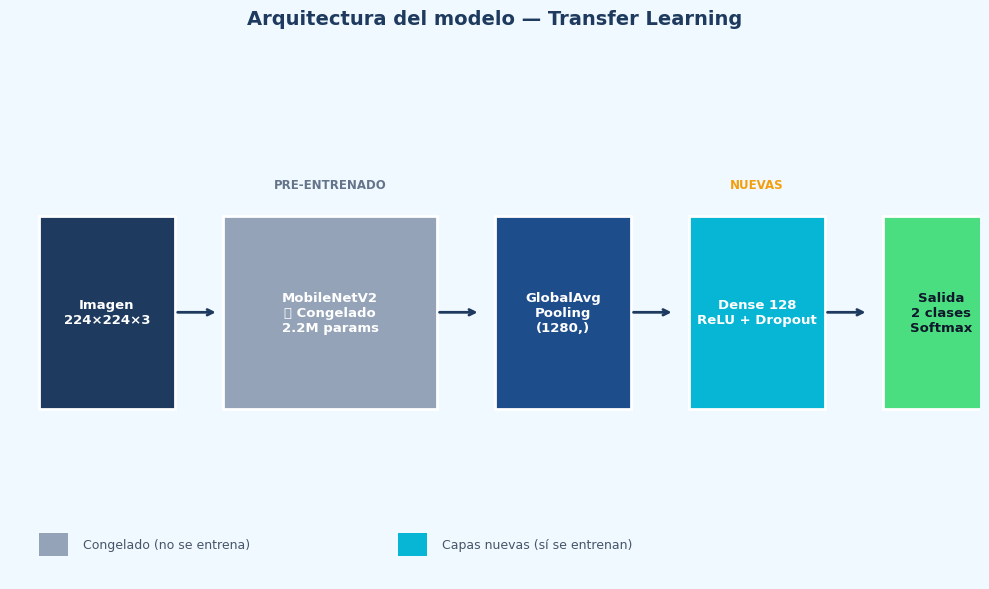

In [11]:
# ─── VISUALIZAR LA ARQUITECTURA ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(0, 10); ax.set_ylim(0, 7)
ax.axis('off')
ax.set_facecolor('#F0F9FF')
fig.patch.set_facecolor('#F0F9FF')
ax.set_title('Arquitectura del modelo — Transfer Learning',
             fontsize=14, fontweight='bold', color='#1E3A5F', pad=10)

bloques = [
    {'label':'Imagen\n224×224×3',       'x':0.3, 'w':1.4, 'color':'#1E3A5F',  'tc':'white', 'tag':None},
    {'label':'MobileNetV2\n🔒 Congelado\n2.2M params', 'x':2.2, 'w':2.2, 'color':'#94A3B8', 'tc':'white', 'tag':'PRE-ENTRENADO'},
    {'label':'GlobalAvg\nPooling\n(1280,)',    'x':5.0, 'w':1.4, 'color':'#1E4D8C',  'tc':'white', 'tag':None},
    {'label':'Dense 128\nReLU + Dropout', 'x':7.0, 'w':1.4, 'color':'#06B6D4',  'tc':'white', 'tag':'NUEVAS'},
    {'label':f'Salida\n{N_CLASES} clases\nSoftmax',   'x':9.0, 'w':1.2, 'color':'#4ADE80',  'tc':'#0F172A', 'tag':None},
]

for b in bloques:
    rect = plt.Rectangle((b['x'], 2.2), b['w'], 2.5,
                          facecolor=b['color'], edgecolor='white', linewidth=2, zorder=3)
    ax.add_patch(rect)
    ax.text(b['x'] + b['w']/2, 3.45, b['label'],
            ha='center', va='center', color=b['tc'], fontsize=9.5, fontweight='bold',
            multialignment='center', zorder=4)
    if b['tag']:
        color_tag = '#F59E0B' if 'NUEVA' in b['tag'] else '#64748B'
        ax.text(b['x'] + b['w']/2, 5.1, b['tag'],
                ha='center', va='center', color=color_tag, fontsize=8.5, fontweight='bold', zorder=4)

# Flechas
flechas = [1.7, 4.4, 6.4, 8.4]
for fx in flechas:
    ax.annotate('', xy=(fx+0.45, 3.45), xytext=(fx, 3.45),
                arrowprops=dict(arrowstyle='->', color='#1E3A5F', lw=2), zorder=5)

# Leyenda
ax.add_patch(plt.Rectangle((0.3, 0.3), 0.3, 0.3, facecolor='#94A3B8', zorder=3))
ax.text(0.75, 0.45, 'Congelado (no se entrena)', va='center', fontsize=9, color='#475569')
ax.add_patch(plt.Rectangle((4.0, 0.3), 0.3, 0.3, facecolor='#06B6D4', zorder=3))
ax.text(4.45, 0.45, 'Capas nuevas (sí se entrenan)', va='center', fontsize=9, color='#475569')

plt.tight_layout()
plt.show()

---
## Parte 3 — Preparar los datos con Data Augmentation

Con pocas fotos, **Data Augmentation** es clave. Genera variantes de cada imagen para que el modelo vea más diversidad sin necesitar más fotos.

Las transformaciones que vamos a aplicar:
- **Flip horizontal:** espejo de la imagen
- **Rotación leve:** ±15°
- **Zoom:** ±10%
- **Brillo:** variación de iluminación

Found 15 files belonging to 2 classes.
Found 4 files belonging to 2 classes.
Dataset listo:
  Clases detectadas: ['gato', 'perro']
  Batch size: 8


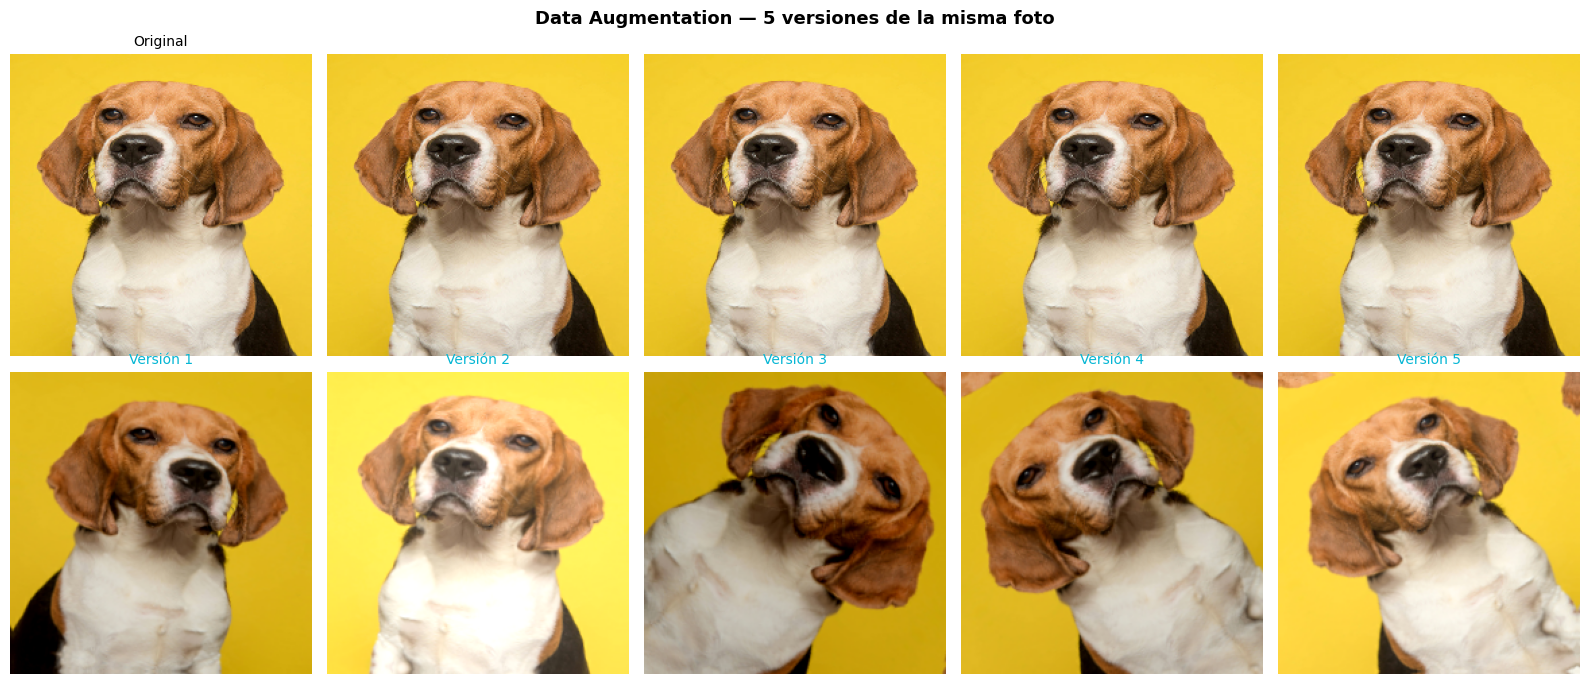

✅ 5 versiones distintas generadas de la misma foto — sin agregar más imágenes.


In [12]:
# ─── DEFINIR DATA AUGMENTATION ───────────────────────────────────────
augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.2),
], name='augmentation')

# ─── DATASETS ────────────────────────────────────────────────────────
train_ds = image_dataset_from_directory(
    'dataset/train',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=True,
    seed=42
)

val_ds = image_dataset_from_directory(
    'dataset/val',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    seed=42
)

# Aplicar augmentation solo al train
AUTOTUNE = tf.data.AUTOTUNE
train_ds_aug = train_ds.map(
    lambda x, y: (augmentation(x, training=True), y),
    num_parallel_calls=AUTOTUNE
).cache().prefetch(AUTOTUNE)

val_ds_prep = val_ds.cache().prefetch(AUTOTUNE)

print(f'Dataset listo:')
print(f'  Clases detectadas: {train_ds.class_names}')
print(f'  Batch size: {BATCH_SIZE}')

# Mostrar ejemplos de augmentation
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
fig.suptitle('Data Augmentation — 5 versiones de la misma foto',
             fontsize=13, fontweight='bold')

# Tomar la primera imagen del primer batch
for images, labels in train_ds.take(1):
    img_original = images[0:1]
    break

for col in range(5):
    # Original
    axes[0][col].imshow(img_original[0].numpy().astype('uint8'))
    axes[0][col].set_title('Original' if col == 0 else '', fontsize=10)
    axes[0][col].axis('off')
    # Augmentada
    img_aug = augmentation(img_original, training=True)
    axes[1][col].imshow(img_aug[0].numpy().clip(0,255).astype('uint8'))
    axes[1][col].set_title(f'Versión {col+1}', fontsize=10, color='#06B6D4')
    axes[1][col].axis('off')

axes[0][0].set_ylabel('Original', fontsize=11, fontweight='bold', color='#1E3A5F')
axes[1][0].set_ylabel('Augmentada', fontsize=11, fontweight='bold', color='#06B6D4')
plt.tight_layout()
plt.show()
print('✅ 5 versiones distintas generadas de la misma foto — sin agregar más imágenes.')

---
## Parte 4 — Entrenar el modelo (Fase 1: capas congeladas)

En la primera fase entrenamos **solo las capas nuevas**. MobileNetV2 no se toca.
Esto es rápido y estable — ideal para pocas fotos.

In [13]:
# ─── FASE 1: ENTRENAMIENTO CON BASE CONGELADA ─────────────────────────
EPOCHS_FASE1 = 15

# Callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy', patience=5, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, verbose=1
    ),
]

print('🔒 Fase 1: entrenando solo las capas nuevas (MobileNetV2 congelado)')
print(f'   Épocas máximas: {EPOCHS_FASE1} (Early Stopping puede parar antes)')
print()

historia1 = modelo.fit(
    train_ds_aug,
    validation_data=val_ds_prep,
    epochs=EPOCHS_FASE1,
    callbacks=callbacks,
    verbose=1
)

val_acc_f1 = max(historia1.history['val_accuracy'])
print(f'\n✅ Fase 1 completada')
print(f'   Mejor accuracy en validación: {val_acc_f1*100:.1f}%')

🔒 Fase 1: entrenando solo las capas nuevas (MobileNetV2 congelado)
   Épocas máximas: 15 (Early Stopping puede parar antes)

Epoch 1/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 54s 35s/step - accuracy: 0.8000 - loss: 0.4788 - val_accuracy: 0.7500 - val_loss: 0.3318 - learning_rate: 0.0010
Epoch 2/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9333 - loss: 0.1155 - val_accuracy: 0.7500 - val_loss: 0.2150 - learning_rate: 0.0010
Epoch 3/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 1.0000 - loss: 0.0294 - val_accuracy: 0.7500 - val_loss: 0.2503 - learning_rate: 0.0010
Epoch 4/15
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 1.0000 - loss: 0.0024 - val_accuracy: 0.7500 - val_loss: 0.2986 - learning_rate: 0.0010
Epoch 5/15
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 1.0000 - loss: 0.0017
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 1.0000 - loss: 0.0199 - val_accuracy: 0.7500 - val_loss: 0.3396 - lear

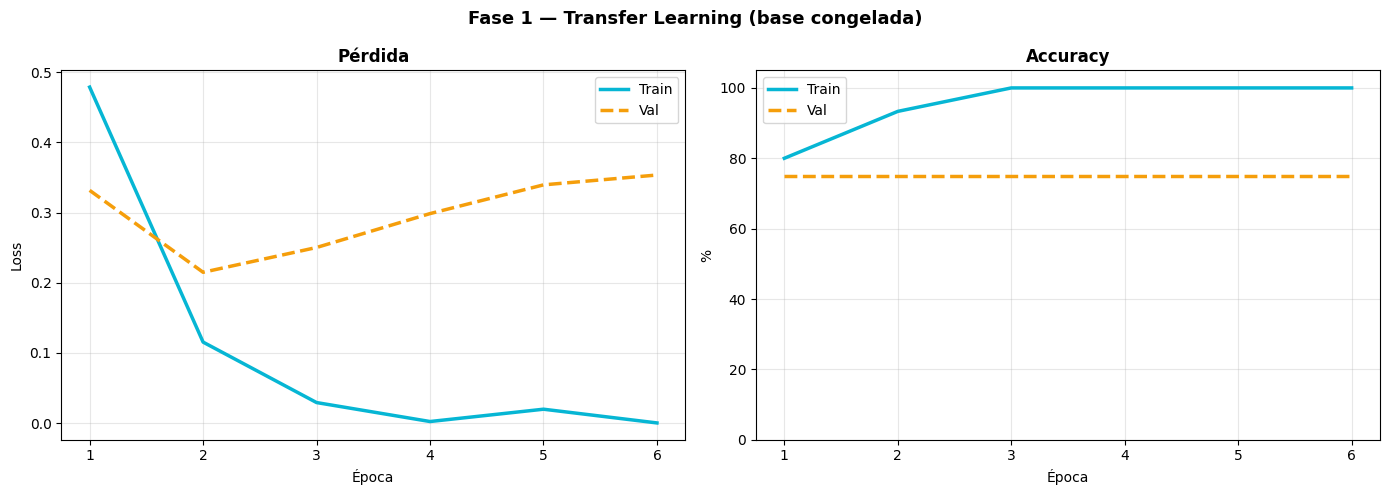

Accuracy final → Train: 100.0%  |  Val: 75.0%


In [14]:
# ─── GRÁFICOS FASE 1 ──────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Fase 1 — Transfer Learning (base congelada)', fontsize=13, fontweight='bold')

ep = range(1, len(historia1.history['loss'])+1)

ax1.plot(ep, historia1.history['loss'],     '#06B6D4', lw=2.5, label='Train')
ax1.plot(ep, historia1.history['val_loss'], '#F59E0B', lw=2.5, ls='--', label='Val')
ax1.set_title('Pérdida', fontweight='bold'); ax1.set_xlabel('Época'); ax1.set_ylabel('Loss')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(ep, [v*100 for v in historia1.history['accuracy']],     '#06B6D4', lw=2.5, label='Train')
ax2.plot(ep, [v*100 for v in historia1.history['val_accuracy']], '#F59E0B', lw=2.5, ls='--', label='Val')
ax2.set_title('Accuracy', fontweight='bold'); ax2.set_xlabel('Época'); ax2.set_ylabel('%')
ax2.legend(); ax2.grid(alpha=0.3); ax2.set_ylim(0, 105)

plt.tight_layout(); plt.show()
print(f'Accuracy final → Train: {historia1.history["accuracy"][-1]*100:.1f}%  |  Val: {historia1.history["val_accuracy"][-1]*100:.1f}%')

---
## Parte 5 — Fine-tuning (Fase 2: descongelar las últimas capas)

En la Fase 2 vamos a **descongelar las últimas 20 capas** de MobileNetV2 y seguir entrenando con un learning rate mucho más bajo.

Esto permite que la red ajuste las representaciones más específicas de tus fotos, partiendo de lo que ya aprendió en Fase 1.

> ⚠️ **Si ya tenés buen accuracy en Fase 1, esta fase puede no ser necesaria.** Solo ejecutala si querés mejorar más.

In [15]:
# ─── FASE 2: FINE-TUNING ──────────────────────────────────────────────
EPOCHS_FASE2  = 10
CAPAS_A_DESCONGELAR = 20   # últimas 20 capas de MobileNetV2

# Descongelar las últimas N capas
base_model.trainable = True
for capa in base_model.layers[:-CAPAS_A_DESCONGELAR]:
    capa.trainable = False

# Re-compilar con learning rate MUY bajo (para no destruir los pesos pre-entrenados)
modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

params_trainable = sum([np.prod(v.shape) for v in modelo.trainable_variables])
print(f'🔓 Fase 2: {CAPAS_A_DESCONGELAR} últimas capas de MobileNetV2 descongeladas')
print(f'   Parámetros a entrenar ahora: {params_trainable:,}')
print(f'   Learning rate: 1e-5 (muy bajo para no sobrescribir lo aprendido)')
print()

callbacks_f2 = [
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy', patience=4, restore_best_weights=True, verbose=1
    ),
]

historia2 = modelo.fit(
    train_ds_aug,
    validation_data=val_ds_prep,
    epochs=EPOCHS_FASE2,
    callbacks=callbacks_f2,
    verbose=1
)

val_acc_f2 = max(historia2.history['val_accuracy'])
print(f'\n✅ Fase 2 completada')
print(f'   Mejor accuracy Fase 1: {val_acc_f1*100:.1f}%')
print(f'   Mejor accuracy Fase 2: {val_acc_f2*100:.1f}%')
print(f'   Mejora:                +{(val_acc_f2-val_acc_f1)*100:.1f}%')

🔓 Fase 2: 20 últimas capas de MobileNetV2 descongeladas
   Parámetros a entrenar ahora: 1,370,306
   Learning rate: 1e-5 (muy bajo para no sobrescribir lo aprendido)

Epoch 1/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 27s 12s/step - accuracy: 0.8667 - loss: 0.3127 - val_accuracy: 0.7500 - val_loss: 0.3319
Epoch 2/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8667 - loss: 0.1743 - val_accuracy: 0.7500 - val_loss: 0.3299
Epoch 3/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 1.0000 - loss: 0.1549 - val_accuracy: 0.7500 - val_loss: 0.3267
Epoch 4/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 1.0000 - loss: 0.1557 - val_accuracy: 0.7500 - val_loss: 0.3233
Epoch 5/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 1.0000 - loss: 0.1371 - val_accuracy: 0.7500 - val_loss: 0.3200
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 1.

✅ Fase 2 completada
   Mejor accuracy Fase 1: 75.0%
   Mejor accuracy Fase 2: 75.0%
   Mejora:                +0.0%


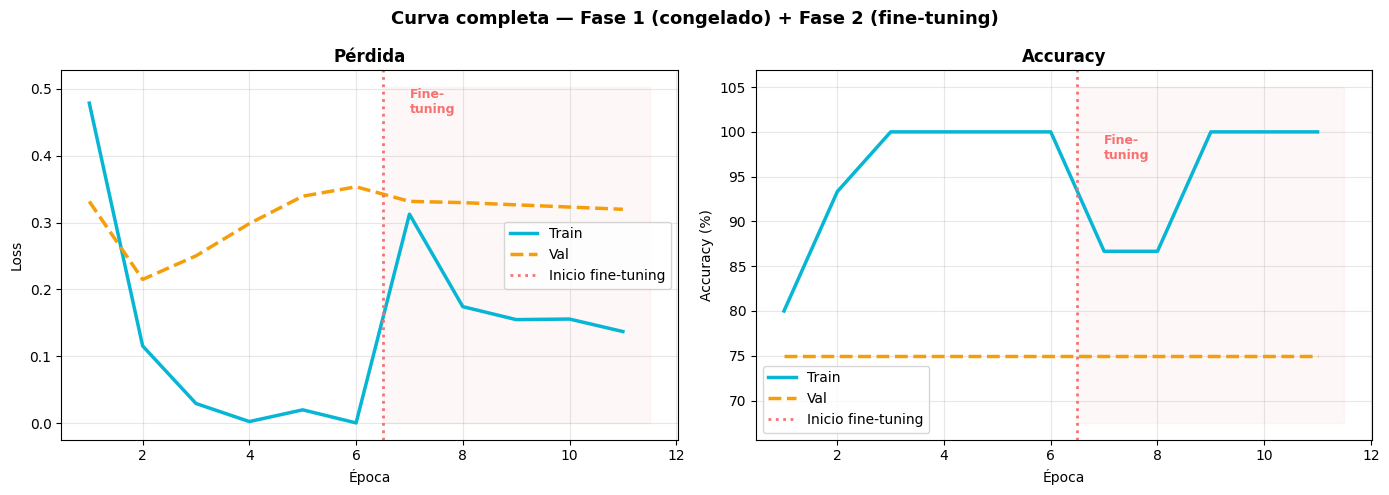

In [16]:
# ─── CURVA COMPLETA (FASE 1 + FASE 2) ────────────────────────────────
acc_total     = historia1.history['accuracy']     + historia2.history['accuracy']
val_acc_total = historia1.history['val_accuracy'] + historia2.history['val_accuracy']
loss_total    = historia1.history['loss']         + historia2.history['loss']
val_loss_total= historia1.history['val_loss']     + historia2.history['val_loss']
ep_total      = range(1, len(acc_total)+1)
split_ep      = len(historia1.history['accuracy'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Curva completa — Fase 1 (congelado) + Fase 2 (fine-tuning)',
             fontsize=13, fontweight='bold')

for ax, train_h, val_h, ylabel in [
    (ax1, loss_total,    val_loss_total,    'Loss'),
    (ax2, [v*100 for v in acc_total], [v*100 for v in val_acc_total], 'Accuracy (%)')
]:
    ax.plot(ep_total, train_h, '#06B6D4', lw=2.5, label='Train')
    ax.plot(ep_total, val_h,   '#F59E0B', lw=2.5, ls='--', label='Val')
    ax.axvline(x=split_ep+0.5, color='#F87171', lw=2, ls=':', label='Inicio fine-tuning')
    ax.fill_betweenx([min(train_h+val_h)*0.9, max(train_h+val_h)*1.05],
                     split_ep+0.5, len(ep_total)+0.5, alpha=0.05, color='#F87171')
    ax.set_xlabel('Época'); ax.set_ylabel(ylabel)
    ax.legend(); ax.grid(alpha=0.3)
    ax.text(split_ep+1, max(train_h+val_h)*0.97, 'Fine-\ntuning',
            fontsize=9, color='#F87171', fontweight='bold')

ax1.set_title('Pérdida', fontweight='bold')
ax2.set_title('Accuracy', fontweight='bold')
plt.tight_layout(); plt.show()

---
## Parte 6 — Probar el modelo con una foto nueva

Subí una foto que **no estaba en el dataset** y veamos qué predice el modelo.

In [17]:
# ─── DIAGNÓSTICO RÁPIDO ANTES DE PREDECIR ────────────────────────────
# Ejecutá esta celda para verificar que el modelo está funcionando
# antes de subir una foto nueva.

print('Verificando modelo sobre el set de validación...')
print(f'  Categorías (orden interno): {CATEGORIAS}')
print()

for images, labels in val_ds.take(1):
    preds = modelo.predict(images, verbose=0)
    for i in range(len(images)):
        real     = CATEGORIAS[int(labels[i])]
        pred_idx = int(np.argmax(preds[i]))
        pred     = CATEGORIAS[pred_idx]
        conf     = preds[i][pred_idx] * 100
        ok       = '✅' if real == pred else '❌'
        print(f'  {ok} Real: {real:10s} → Pred: {pred:10s} ({conf:.1f}%)')
        print(f'     Probabilidades: { {cat: f"{preds[i][j]*100:.1f}%" for j, cat in enumerate(CATEGORIAS)} }')

# Si ves que SIEMPRE predice la misma categoría → el modelo no convergió.
# Causas más comunes:
#   1. Muy pocas fotos (< 8 por categoría)
#   2. Las fotos son muy similares entre categorías
#   3. El modelo necesita más épocas


Verificando modelo sobre el set de validación...
  Categorías (orden interno): ['gato', 'perro']

  ❌ Real: perro      → Pred: gato       (58.6%)
     Probabilidades: {'gato': '58.6%', 'perro': '41.4%'}
  ✅ Real: perro      → Pred: perro      (77.2%)
     Probabilidades: {'gato': '22.8%', 'perro': '77.2%'}
  ✅ Real: gato       → Pred: gato       (97.0%)
     Probabilidades: {'gato': '97.0%', 'perro': '3.0%'}
  ✅ Real: gato       → Pred: gato       (85.6%)
     Probabilidades: {'gato': '85.6%', 'perro': '14.4%'}


📸 Subí una foto nueva para predecir (que no estaba en el dataset):



Saving dog2.png to dog2.png


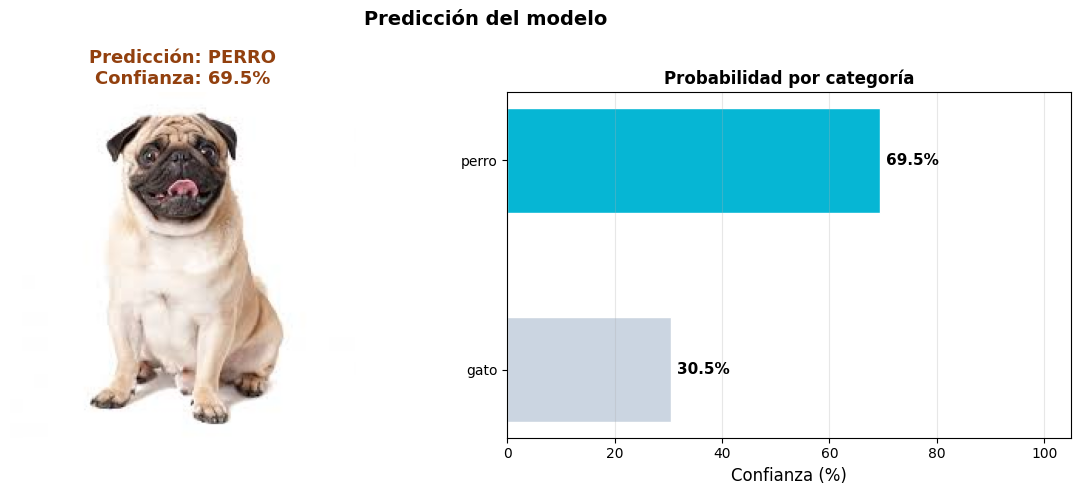

In [18]:
# ─── SUBIR FOTO DE PRUEBA ─────────────────────────────────────────────
print('📸 Subí una foto nueva para predecir (que no estaba en el dataset):\n')
foto_test = files.upload()

nombre_foto = list(foto_test.keys())[0]

# Preprocesar
img = load_img(nombre_foto, target_size=IMG_SIZE)
img_array = img_to_array(img)
img_batch = np.expand_dims(img_array, axis=0)   # (1, 224, 224, 3)

# Predecir
raw = modelo.predict(img_batch, verbose=0)[0]
# Normalizar: funciona tanto con Dense(1,sigmoid) como Dense(N,softmax)
if raw.ndim == 0 or len(raw) == 1:
    # Caso sigmoid binario: convertir a [1-p, p]
    p = float(raw) if raw.ndim == 0 else float(raw[0])
    probs = np.array([1 - p, p])
else:
    probs = raw
clase_pred  = int(np.argmax(probs))
nombre_pred = CATEGORIAS[clase_pred]
confianza   = probs[clase_pred] * 100

# Visualizar
fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Predicción del modelo', fontsize=14, fontweight='bold')

ax_img.imshow(img)
ax_img.axis('off')
color_titulo = '#166534' if confianza > 70 else '#92400E'
ax_img.set_title(f'Predicción: {nombre_pred.upper()}\nConfianza: {confianza:.1f}%',
                 fontsize=13, fontweight='bold', color=color_titulo)

# Barra de probabilidades
colors = ['#06B6D4' if i == clase_pred else '#CBD5E1' for i in range(N_CLASES)]
bars = ax_bar.barh(CATEGORIAS, probs * 100, color=colors, edgecolor='white', height=0.5)
ax_bar.set_xlabel('Confianza (%)', fontsize=12)
ax_bar.set_title('Probabilidad por categoría', fontsize=12, fontweight='bold')
ax_bar.set_xlim(0, 105)
ax_bar.grid(axis='x', alpha=0.3)
for bar, p in zip(bars, probs):
    ax_bar.text(p*100 + 1, bar.get_y() + bar.get_height()/2,
               f'{p*100:.1f}%', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

---
## Parte 7 — El experimento clave: ¿qué pasa sin Transfer Learning?

Este es el experimento que valida toda la teoría. Vamos a entrenar **exactamente la misma arquitectura pero sin los pesos pre-entrenados** — pesos aleatorios desde cero.

Con tan pocas fotos, ¿puede aprender algo?

In [19]:
# ─── ENTRENAR DESDE CERO (sin Transfer Learning) ─────────────────────
print('Construyendo modelo SIN pesos pre-entrenados...')

# Nuevo base model con pesos ALEATORIOS
base_scratch = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights=None    # ← SIN ImageNet, pesos aleatorios
)
base_scratch.trainable = True

modelo_scratch = keras.Sequential([
    layers.Rescaling(1./127.5, offset=-1, input_shape=(224, 224, 3)),
    base_scratch,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(N_CLASES, activation='softmax'),
], name='scratch_model')

modelo_scratch.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print('Entrenando desde cero (misma arquitectura, mismas fotos, sin conocimiento previo)...')

historia_scratch = modelo_scratch.fit(
    train_ds_aug,
    validation_data=val_ds_prep,
    epochs=15,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True, verbose=0)],
    verbose=0
)

val_acc_scratch = max(historia_scratch.history['val_accuracy'])
print(f'\n📊 COMPARACIÓN FINAL:')
print(f'  Con Transfer Learning:    {val_acc_f2*100:.1f}%  ✅')
print(f'  Sin Transfer Learning:    {val_acc_scratch*100:.1f}%')
print(f'  Diferencia:              +{(val_acc_f2-val_acc_scratch)*100:.1f}% a favor del Transfer Learning')

Construyendo modelo SIN pesos pre-entrenados...
Entrenando desde cero (misma arquitectura, mismas fotos, sin conocimiento previo)...

📊 COMPARACIÓN FINAL:
  Con Transfer Learning:    75.0%  ✅
  Sin Transfer Learning:    50.0%
  Diferencia:              +25.0% a favor del Transfer Learning


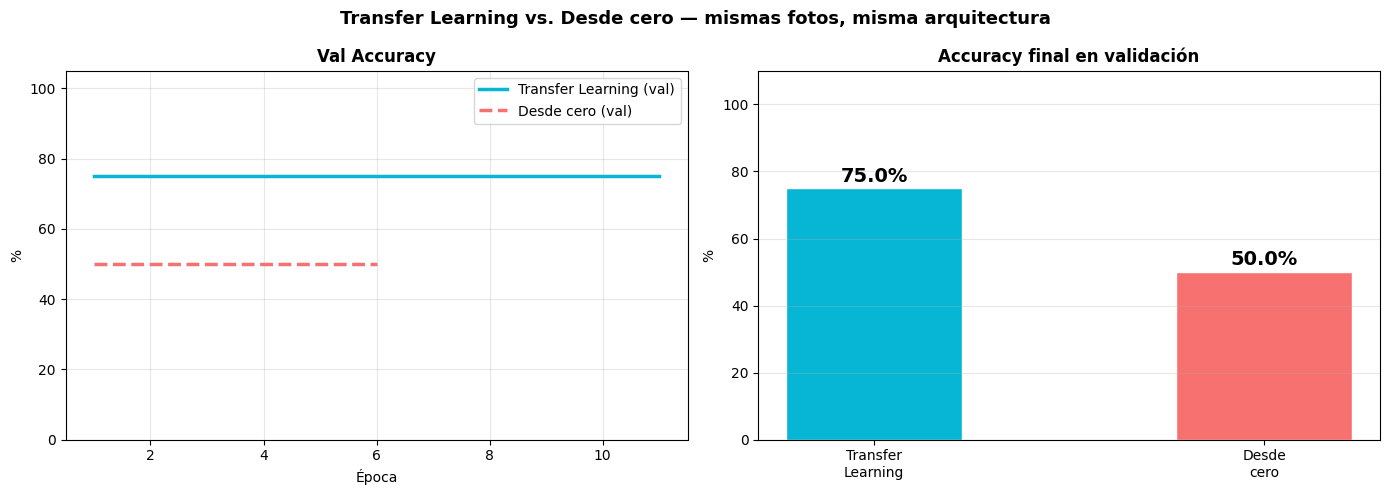

💡 Con pocas fotos, Transfer Learning es la diferencia entre un modelo que funciona
   y uno que no aprende nada. Cuantas menos fotos tenés, más importa el conocimiento previo.


In [20]:
# ─── GRÁFICO COMPARATIVO ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Transfer Learning vs. Desde cero — mismas fotos, misma arquitectura',
             fontsize=13, fontweight='bold')

ep_tl = range(1, len(acc_total)+1)
ep_sc = range(1, len(historia_scratch.history['accuracy'])+1)

# Accuracy
axes[0].plot(ep_tl, [v*100 for v in val_acc_total], '#06B6D4', lw=2.5, label='Transfer Learning (val)')
axes[0].plot(ep_sc, [v*100 for v in historia_scratch.history['val_accuracy']], '#F87171', lw=2.5, ls='--', label='Desde cero (val)')
axes[0].set_title('Val Accuracy', fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('%')
axes[0].legend(); axes[0].grid(alpha=0.3); axes[0].set_ylim(0, 105)

# Barras resumen
modelos = ['Transfer\nLearning', 'Desde\ncero']
accs    = [val_acc_f2*100, val_acc_scratch*100]
colors  = ['#06B6D4', '#F87171']
bars = axes[1].bar(modelos, accs, color=colors, width=0.45, edgecolor='white')
axes[1].set_title('Accuracy final en validación', fontweight='bold')
axes[1].set_ylabel('%'); axes[1].set_ylim(0, 110)
axes[1].grid(axis='y', alpha=0.3)
for bar, acc in zip(bars, accs):
    axes[1].text(bar.get_x() + bar.get_width()/2, acc + 2,
                f'{acc:.1f}%', ha='center', fontsize=14, fontweight='bold')

plt.tight_layout(); plt.show()

print('💡 Con pocas fotos, Transfer Learning es la diferencia entre un modelo que funciona')
print('   y uno que no aprende nada. Cuantas menos fotos tenés, más importa el conocimiento previo.')

---
## Parte 8 — ¿Qué está mirando la red? (Grad-CAM)

Grad-CAM (Gradient-weighted Class Activation Mapping) genera un **mapa de calor** que muestra qué zona de la imagen activó más la predicción. Es una técnica de **explicabilidad** — entender por qué la red decidió lo que decidió.

Última capa convolucional: Conv_1_bn


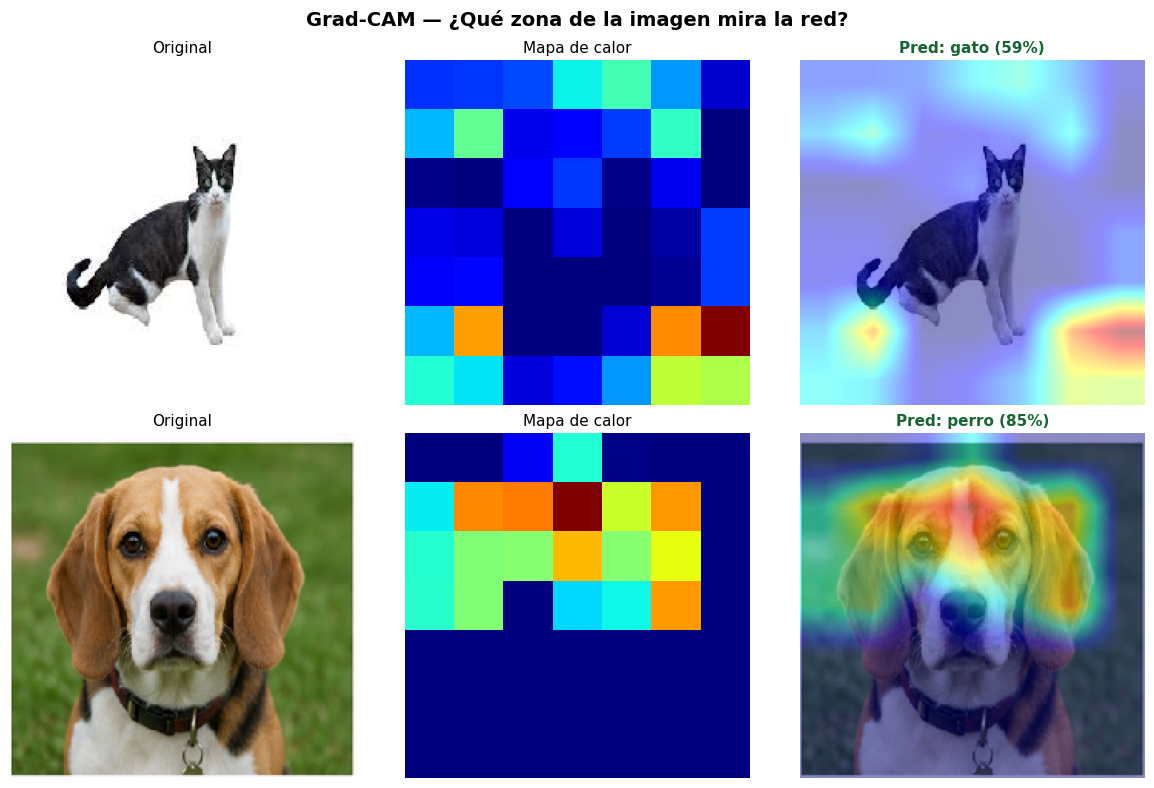

🔴 Las zonas rojas = donde la red puso más atención para tomar la decisión.
   Si el mapa está en la zona equivocada, el modelo puede estar aprendiendo el fondo, no el objeto.


In [21]:
# ─── GRAD-CAM ─────────────────────────────────────────────────────────
import cv2
import tensorflow as tf
from tensorflow import keras
import numpy as np

def get_gradcam_heatmap(model, img_array, last_conv_layer_name):
    """Calcula el mapa de calor Grad-CAM para la clase predicha"""

    mobilenet_v2_layer = model.get_layer('mobilenetv2_1.00_224')

    # ── Un único sub-modelo que emite DOS salidas en un solo pase ──────
    grad_model = keras.Model(
        inputs=mobilenet_v2_layer.input,
        outputs=[
            mobilenet_v2_layer.get_layer(last_conv_layer_name).output,  # conv features
            mobilenet_v2_layer.output                                    # salida MobileNet
        ]
    )

    # Reescalado manual (equivale a la capa Rescaling del modelo original)
    img_float   = tf.cast(img_array, tf.float32)
    img_rescaled = img_float / 127.5 - 1.0   # rango [-1, 1] que espera MobileNetV2

    # Capas de la cabeza de clasificación
    gap_layer     = model.get_layer('global_average_pooling2d')
    dense_layer   = model.get_layer('dense')
    dropout_layer = model.get_layer('dropout')
    output_layer  = model.get_layer('dense_1')

    with tf.GradientTape() as tape:
        # Un solo pase → conv_out y mobilenet_out comparten el mismo grafo
        conv_out_val, mobilenet_out = grad_model(img_rescaled)

        # Cabeza de clasificación
        x = gap_layer(mobilenet_out)
        x = dense_layer(x)
        x = dropout_layer(x, training=False)   # training=False para eval
        pred_val = output_layer(x)

        pred_index   = tf.argmax(pred_val[0])
        class_channel = pred_val[:, pred_index]

    # Ahora grads NO será None porque conv_out_val y class_channel
    # están en el mismo grafo diferenciable
    grads       = tape.gradient(class_channel, conv_out_val)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_out_val = conv_out_val[0]
    heatmap      = conv_out_val @ pooled_grads[..., tf.newaxis]
    heatmap      = tf.squeeze(heatmap)
    heatmap      = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()


def overlay_gradcam(img_pil, heatmap, alpha=0.45):
    """Superpone el mapa de calor sobre la imagen original"""
    img_np = np.array(img_pil.resize((224, 224)))
    heatmap_resized = cv2.resize(heatmap, (224, 224))
    heatmap_colored = cv2.applyColorMap(
        (heatmap_resized * 255).astype('uint8'), cv2.COLORMAP_JET
    )
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    superposed = (img_np * (1 - alpha) + heatmap_colored * alpha).astype('uint8')
    return superposed

# Aplicar a las primeras imágenes de cada categoría
# Buscar el nombre de la última capa convolucional de MobileNetV2
last_conv = None
for layer in reversed(base_model.layers):
    if 'conv' in layer.name.lower():
        last_conv = layer.name
        break
print(f'Última capa convolucional: {last_conv}')

fig, axes = plt.subplots(len(CATEGORIAS), 3, figsize=(12, 4*len(CATEGORIAS)))
if len(CATEGORIAS) == 2:
    axes = axes.reshape(2, 3)
fig.suptitle('Grad-CAM — ¿Qué zona de la imagen mira la red?',
             fontsize=14, fontweight='bold')

for row, cat in enumerate(CATEGORIAS):
    path = f'dataset/train/{cat}'
    imgs = [f for f in os.listdir(path) if f.lower().endswith(('.jpg','.jpeg','.png','.webp'))]
    if not imgs: continue

    img_path = f'{path}/{imgs[0]}'
    img_pil  = load_img(img_path, target_size=IMG_SIZE)
    img_arr  = np.expand_dims(img_to_array(img_pil), 0)

    try:
        heatmap = get_gradcam_heatmap(modelo, img_arr, last_conv)
        overlay = overlay_gradcam(img_pil, heatmap)

        # Predicción
        probs_cam = modelo.predict(img_arr, verbose=0)[0]
        pred_cat  = CATEGORIAS[np.argmax(probs_cam)]
        conf_cam  = probs_cam.max() * 100

        axes[row][0].imshow(img_pil);    axes[row][0].set_title('Original', fontsize=11); axes[row][0].axis('off')
        axes[row][1].imshow(heatmap, cmap='jet'); axes[row][1].set_title('Mapa de calor', fontsize=11); axes[row][1].axis('off')
        axes[row][2].imshow(overlay);    axes[row][2].axis('off')
        color_t = '#166534' if pred_cat == cat else '#991B1B'
        axes[row][2].set_title(f'Pred: {pred_cat} ({conf_cam:.0f}%)', fontsize=11, color=color_t, fontweight='bold')
        axes[row][0].set_ylabel(f'Categoría:\n{cat}', fontsize=11, fontweight='bold', color='#1E3A5F')
    except Exception as e:
        print(f'  ⚠️  Grad-CAM no disponible para {cat}: {e}')
        for col in range(3): axes[row][col].axis('off')

plt.tight_layout(); plt.show()
print('🔴 Las zonas rojas = donde la red puso más atención para tomar la decisión.')
print('   Si el mapa está en la zona equivocada, el modelo puede estar aprendiendo el fondo, no el objeto.')

---
## Resumen de lo que aprendiste hoy

| Concepto | En una oración |
|----------|----------------|
| **Transfer Learning** | Usar el conocimiento de un modelo entrenado en otro problema para resolver el tuyo |
| **Feature extraction** | Congelar la base y solo entrenar las capas nuevas (Fase 1) |
| **Fine-tuning** | Descongelar las últimas capas y ajustar con lr muy bajo (Fase 2) |
| **MobileNetV2** | Red liviana de Google, entrenada en ImageNet (1.4M imágenes, 1000 clases) |
| **Data Augmentation** | Generar variantes de tus imágenes para simular más datos |
| **Grad-CAM** | Visualizar qué parte de la imagen activó la predicción — explicabilidad |
| **La gran lección** | Con Transfer Learning, 20 fotos pueden superar a 2000 fotos sin él |

---
**Próxima clase:** Ensemble Learning — combinar múltiples modelos para superar a cualquiera por separado